# Asignación Euler de Expected Shortfall con curvas observadas

## Decisión y alcance
Una mesa desea comparar la contribución a pérdidas de dos tramos de tasa y evaluar sensibilidad de una asignación. Usamos rendimientos **par de Treasury de EE. UU. observados** en 2024–2026, con exposiciones y duraciones hipotéticas. El resultado es un laboratorio de atribución, no capital de una entidad ni P&L de bonos negociados.

Se construyen pérdidas diarias por cambio de tasas de los vencimientos 2 y 10 años, se estima Expected Shortfall histórico al 95 % y se atribuye la media de pérdidas en la cola. Se contrasta una muestra 2024–2025 con un periodo posterior y con una cartera alternativa. La cola fija con pesos iguales por observación permite que las contribuciones sumen exactamente el ES aun en empates, seleccionados establemente por fecha. [Treasury: metodología de curva par](https://home.treasury.gov/policy-issues/financing-the-government/interest-rate-statistics/treasury-yield-curve-methodology); [BCBS: riesgo de mercado](https://www.bis.org/bcbs/publ/d457.htm).

## Resultado de este corte

Con una posición hipotética de USD 1 millón y pesos 50/50, el ES histórico del entrenamiento fue USD 5.932; el tramo a diez años aportó USD 4.800 y el de dos años USD 1.132. En 2026 hubo seis excedencias del umbral en 216 observaciones. La comparación depende de duraciones supuestas y no valida capital económico institucional.

## Datos y supuestos
Fuentes: instantáneas de la curva diaria guardadas en `03-financial-risk/02-market-and-model-risk/var-es-tres-metodos/data/raw/`; fecha de captura 2026-11-10 según el companion. Unidades: rendimiento en porcentaje anual, exposición USD 1 millón, duraciones modificadas supuestas de 1,9 y 8 años; asignación base 50/50. Una variación de 1 punto porcentual es 0,01 en decimal. Se omiten convexidad, carry, composición del bono y costos. Las tasas par no son precios ejecutables de un bono específico.

Estimación: 2024–2025. Evaluación descriptiva: 2026 hasta el último día del archivo. No se ajustan parámetros ni se toma una decisión real de inversión.

In [1]:
from pathlib import Path
import hashlib, numpy as np, pandas as pd, matplotlib.pyplot as plt
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'03-financial-risk').is_dir())
plt.rcParams.update({'figure.figsize':(9,4),'axes.grid':True,'grid.alpha':0.25})

In [2]:
folder=root/'03-financial-risk/02-market-and-model-risk/var-es-tres-metodos/data/raw'
files=[folder/f'daily-treasury-yield-curve-{year}.csv' for year in ('2024','2025','2026-11-10')]
for p in files: print(p.name,'SHA-256',hashlib.sha256(p.read_bytes()).hexdigest())
frames=[pd.read_csv(p,usecols=['Date','2 Yr','10 Yr']) for p in files]
rates=pd.concat(frames,ignore_index=True); rates['date']=pd.to_datetime(rates.Date,format='%m/%d/%Y'); rates=rates.sort_values('date')
assert not rates.date.duplicated().any()
for c in ['2 Yr','10 Yr']: rates[c]=pd.to_numeric(rates[c],errors='coerce')
print('Filas, faltantes por tenor:',len(rates),rates[['2 Yr','10 Yr']].isna().sum().to_dict())
rates=rates.dropna(subset=['2 Yr','10 Yr']).set_index('date'); rates.head(3)

daily-treasury-yield-curve-2024.csv SHA-256 6775840b76cd7fd41121f61d6f6c60184eca6b2ba49954ec7372c463cbeef34d
daily-treasury-yield-curve-2025.csv SHA-256 cf2fa3da7f160384b63d2ead698532b1d76cd9f789ce4911e2304db85b14e6d5
daily-treasury-yield-curve-2026-11-10.csv SHA-256 782e0953ac34dd4c9751bc061feae3b1a2e18f0be8c7c181a3d2a472d1bdcbe5
Filas, faltantes por tenor: 715 {'2 Yr': 0, '10 Yr': 0}


,Date,2 Yr,10 Yr
date,,,
2024-01-02,01/02/2024,4.33,3.95
2024-01-03,01/03/2024,4.33,3.91
2024-01-04,01/04/2024,4.38,3.99


## Transformación y partición
Para cada tramo, pérdida sobre nominal = duración × cambio de rendimiento decimal. No se rellenan tasas faltantes; tras eliminarlas, los cambios pueden abarcar varias sesiones. La fecha y el orden se verifican antes de dividir.

In [3]:
delta=rates[['2 Yr','10 Yr']].diff().dropna()/100
assert delta.index.is_unique and delta.index.is_monotonic_increasing
loss=delta.mul([1.9,8.0],axis=1).rename(columns={'2 Yr':'2 años','10 Yr':'10 años'})
train=loss.loc[:'2025-12-31']; test=loss.loc['2026-01-01':]
assert len(train)>100 and len(test)>30
print('Entrenamiento:',len(train),train.index.min().date(),train.index.max().date())
print('Evaluación:',len(test),test.index.min().date(),test.index.max().date())

Entrenamiento: 498 2024-01-03 2025-12-31
Evaluación: 216 2026-01-02 2026-11-10


## ES y contribuciones por escenario
Para un conjunto de pérdidas $L_t=\sum_i L_{it}$ seleccionamos las $k=\lceil0.05n\rceil$ pérdidas más altas. La contribución es la media de la pérdida de cada tramo en los **mismos** escenarios de cola; sumar contribuciones reproduce exactamente el ES estimado. No aplicamos atribuciones a un cuantil con interpolación incompatible.

In [4]:
notional=1_000_000
def tail_attribution(frame, weights, alpha=.95):
    components=frame.mul(np.asarray(weights)*notional,axis=1)
    total=components.sum(axis=1); k=int(np.ceil((1-alpha)*len(total)))
    positions=np.argsort(-total.to_numpy(),kind='stable')[:k]
    tail=components.iloc[positions]; rc=tail.mean(); es=float(total.iloc[positions].mean())
    assert np.isclose(rc.sum(),es,rtol=1e-12,atol=1e-8)
    return es,rc,k,float(total.iloc[positions].min())
es,rc,k,threshold=tail_attribution(train,[.5,.5]);print('Escenarios de cola:',k,'| umbral empírico USD:',round(threshold,2),'| ES USD:',round(es,2));rc.to_frame('contribución USD')

Escenarios de cola: 25 | umbral empírico USD: 4435.0 | ES USD: 5932.4


,contribución USD
2 años,1132.4
10 años,4800.0


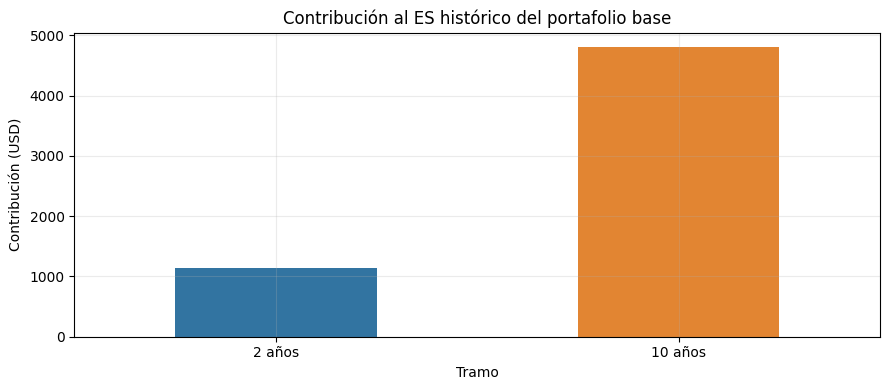

In [5]:
ax=rc.plot.bar(color=['#3274a1','#e28532'],title='Contribución al ES histórico del portafolio base')
ax.set(xlabel='Tramo',ylabel='Contribución (USD)',xticklabels=rc.index);ax.tick_params(axis='x',rotation=0);plt.tight_layout();plt.show()

## Comparación y evaluación temporal
Comparamos la cartera base con 75 % a 2 años y 25 % a 10 años. El umbral fijado en entrenamiento se confronta con los datos posteriores; la proporción de excedencias es descriptiva y puede variar por régimen. Las estimaciones no implican una estrategia óptima.

In [6]:
rows=[]
for name,w in [('Base 50/50',[.5,.5]),('Alternativa 75/25',[.75,.25])]:
    e,r,k,cut=tail_attribution(train,w); total_test=test.mul(np.asarray(w)*notional,axis=1).sum(axis=1)
    realised_es,_,kt,_=tail_attribution(test,w)
    rows.append({'cartera':name,'ES_entrenamiento_USD':e,'umbral_USD':cut,'excedencias_2026':int((total_test>cut).sum()),'n_2026':len(test),'tasa_2026':(total_test>cut).mean(),'ES_descriptivo_2026_USD':realised_es})
pd.DataFrame(rows).set_index('cartera').round(3)

,ES_entrenamiento_USD,umbral_USD,excedencias_2026,n_2026,tasa_2026,ES_descriptivo_2026_USD
cartera,,,,,,
Base 50/50,5932.4,4435.0,6,216,0.028,5056.818
Alternativa 75/25,4111.1,3197.5,8,216,0.037,3696.818


## Robustez: bootstrap por bloques
Remuestreamos bloques consecutivos de 10 observaciones, preservando dependencia dentro de cada bloque. Los intervalos percentiles expresan variabilidad bajo este procedimiento; no corrigen cambios de régimen ni son garantías de cobertura. Semilla fija, 300 réplicas.

In [7]:
rng=np.random.default_rng(13); values=train.to_numpy(); N=len(values); block=10; B=300; draws=[]
for _ in range(B):
    starts=rng.integers(0,N-block+1,size=int(np.ceil(N/block)))
    ids=np.concatenate([np.arange(s,s+block) for s in starts])[:N]
    e,r,_,_=tail_attribution(pd.DataFrame(values[ids],columns=train.columns),[.5,.5]); draws.append([e,*r])
boot=pd.DataFrame(draws,columns=['ES total','2 años','10 años']);boot.quantile([.025,.5,.975]).T.rename(columns={.025:'p2.5',.5:'mediana',.975:'p97.5'}).round(2)

,p2.5,mediana,p97.5
ES total,5200.86,5971.1,6693.03
2 años,911.81,1124.8,1280.79
10 años,4247.60,4832.0,5544.40


## Interpretación y límites
La asignación explica el ES bajo el escenario y posiciones elegidos. Comparar la sensibilidad entre carteras ayuda a discutir límites por duración; para decidir capital económico real se necesitan posiciones, curvas y valoraciones de la entidad, horizonte, diversificación entre riesgos, controles de calidad y validación independiente. El bootstrap no convierte la serie histórica en probabilidad futura validada.